# Partie 3 — Regrouper les joueurs par profil statistique (CAH puis k-means)

**Objectif (demande de la prof) :** former des groupes de joueurs qui jouent de la même façon, laisser les données choisir le nombre de groupes entre 8 et 20, puis expliquer pourquoi les joueurs d'un même groupe sont ensemble.

**Démarche :**
1. Reconstruire la table joueur-saison **en laissant les valeurs manquantes en NA** (plus de `fillna(0)`).
2. Garder les joueurs-saisons avec assez de minutes pour que leurs statistiques soient fiables.
3. Construire des variables de style ramenées à 36 minutes, puis les standardiser **saison par saison**.
4. CAH (critère de Ward) pour k = 8 à 20 groupes : méthode du coude puis indice de silhouette pour choisir k.
5. Consolidation par k-means, initialisé avec les centres de la CAH.
6. Interprétation des groupes.

Une ligne = un joueur sur une saison (les transferts sont fusionnés). Le clustering est fait **pour une saison à la fois**.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.options.display.float_format = "{:.2f}".format
pd.options.display.max_columns = 40

ModuleNotFoundError: No module named 'pandas'

## 1. Chargement des données

`lire_csv` accepte les deux versions des fichiers : le CSV d'origine (séparateur `,`) et l'export Numbers (séparateur `;` avec le nom de la table sur la première ligne).

In [2]:
# Dossier qui contient games_details.csv et games.csv :
# ../donnees si le notebook est lancé depuis notebooks/, donnees/ depuis la racine du projet
DOSSIER = Path("../donnees") if Path("../donnees").exists() else Path("donnees")

def lire_csv(chemin):
    with open(chemin, encoding="utf-8") as f:
        ligne1 = f.readline()
        ligne2 = f.readline()
    # Export Numbers : la première ligne contient seulement le nom de la table
    saut = 0 if (";" in ligne1 or "," in ligne1) else 1
    entete = ligne2 if saut else ligne1
    sep = ";" if entete.count(";") > entete.count(",") else ","
    return pd.read_csv(chemin, sep=sep, skiprows=saut, low_memory=False)

details = lire_csv(DOSSIER / "games_details.csv")
games = lire_csv(DOSSIER / "games.csv")
print("games_details :", details.shape, "| games :", games.shape)

games_details : (668628, 29) | games : (26651, 21)


## 2. Table joueur-saison (mêmes étapes que la partie 1, sans remplir les NA)

- matchs de saison régulière uniquement (3e chiffre du `GAME_ID` = 2) ;
- suppression des doublons joueur-match (on garde la dernière ligne, comme en partie 1) ;
- on ne garde que les matchs où le joueur a réellement joué (`MIN` renseigné) ;
- on calcule des **totaux** sur la saison. Les pourcentages sont calculés sur les totaux (`FG3M / FG3A`), donc ils valent NA quand le joueur n'a tenté aucun tir de ce type. **On les laisse en NA.**

In [3]:
details["GAME_ID"] = details["GAME_ID"].astype(str).str.zfill(10)
games["GAME_ID"] = games["GAME_ID"].astype(str).str.zfill(10)

d = details[details["GAME_ID"].str[2] == "2"].copy()
d = d.merge(games[["GAME_ID", "SEASON"]].drop_duplicates("GAME_ID"),
            on="GAME_ID", how="left", validate="many_to_one")
d = d.drop_duplicates(subset=["GAME_ID", "PLAYER_ID"], keep="last")
d = d[d["MIN"].notna()].copy()

m_s = d["MIN"].str.split(":", expand=True).astype(float)
d["MIN_DEC"] = m_s[0] + m_s[1] / 60
d["TITULAIRE"] = d["START_POSITION"].notna()

stats = ["MIN_DEC", "PTS", "FGM", "FGA", "FG3M", "FG3A", "FTM", "FTA",
         "OREB", "DREB", "REB", "AST", "STL", "BLK", "TO", "PF"]

js = d.groupby(["PLAYER_ID", "SEASON"]).agg(
    PLAYER_NAME=("PLAYER_NAME", "last"),
    EQUIPES=("TEAM_ABBREVIATION", lambda x: ", ".join(pd.unique(x))),
    GP=("GAME_ID", "nunique"),
    GS=("TITULAIRE", "sum"),
    **{s: (s, "sum") for s in stats},
).reset_index().rename(columns={"MIN_DEC": "MIN_TOTAL"})

# Pourcentages : NA si aucune tentative (division 0/0), on ne les remplit pas
js["FG_PCT"] = js["FGM"] / js["FGA"].replace(0, np.nan)
js["FG3_PCT"] = js["FG3M"] / js["FG3A"].replace(0, np.nan)
js["FT_PCT"] = js["FTM"] / js["FTA"].replace(0, np.nan)

print("Joueurs-saisons :", len(js))
print("\nValeurs manquantes :")
print(js[["FG_PCT", "FG3_PCT", "FT_PCT"]].isna().sum())

Joueurs-saisons : 9728

Valeurs manquantes :
FG_PCT       44
FG3_PCT    1185
FT_PCT      404
dtype: int64


## 3. Filtre de fiabilité : au moins 500 minutes sur la saison

Un joueur qui a joué 2 matchs peut avoir 100 % à 3 points : ses statistiques ne décrivent pas son style. On garde les joueurs-saisons avec au moins `MIN_MINUTES` minutes jouées (500 minutes ≈ 25 matchs à 20 minutes).

Conséquence sur les NA : après ce filtre, `FG_PCT` et `FT_PCT` n'ont plus de valeur manquante. Il reste des NA sur `FG3_PCT` : ce sont des intérieurs qui ne tentent jamais de tir à 3 points. Leur NA est une information (« ne tire pas à 3 points »), pas un 0 %.

La saison 2022-23 est incomplète dans le fichier (matchs jusqu'en décembre 2022), elle est donc exclue.

In [4]:
MIN_MINUTES = 500
SAISON_MAX = 2021        # 2022-23 est incomplète

base = js[(js["MIN_TOTAL"] >= MIN_MINUTES) & (js["SEASON"] <= SAISON_MAX)].copy()
print("Joueurs-saisons retenus :", len(base), "sur", len(js))
print("\nValeurs manquantes restantes :")
print(base[["FG_PCT", "FG3_PCT", "FT_PCT"]].isna().sum())
print("\nJoueurs retenus par saison :")
print(base.groupby("SEASON").size().to_string())

Joueurs-saisons retenus : 6506 sur 9728

Valeurs manquantes restantes :
FG_PCT       0
FG3_PCT    447
FT_PCT       0
dtype: int64

Joueurs retenus par saison :
SEASON
2003    325
2004    335
2005    323
2006    328
2007    324
2008    329
2009    331
2010    338
2011    331
2012    344
2013    337
2014    366
2015    350
2016    355
2017    353
2018    361
2019    339
2020    362
2021    375


## 4. Variables de style

Les statistiques sont **ramenées à 36 minutes** : un remplaçant qui joue 15 minutes et un titulaire qui en joue 35 deviennent comparables. On décrit **ce que fait** le joueur plutôt que son volume de jeu.

| Variable | Définition | Ce qu'elle mesure |
|---|---|---|
| `PTS_36`, `AST_36`, `TO_36`, `OREB_36`, `DREB_36`, `STL_36`, `BLK_36` | stat totale × 36 / minutes totales | production par 36 minutes |
| `PART_3PTS` | FG3A / FGA | part des tirs pris à 3 points |
| `PART_LF` | FTA / FGA | capacité à obtenir des lancers francs |
| `TS` | PTS / (2 × (FGA + 0,44 × FTA)) | efficacité au tir (« true shooting ») |
| `FT_PCT` | FTM / FTA | adresse aux lancers francs |

**Pourquoi `FG3_PCT` n'est pas utilisé pour former les groupes :** la CAH et les k-means ont besoin d'une valeur pour chaque variable. Il faudrait remplacer les NA (par 0 ou par la moyenne), ce que la prof a demandé d'éviter. On utilise à la place `PART_3PTS`, toujours définie, et on affiche `FG3_PCT` dans l'interprétation des groupes en ignorant les NA.

**Standardisation par saison :** chaque variable est centrée-réduite à l'intérieur de sa saison (z = (x − moyenne) / écart-type). Un joueur est comparé aux joueurs de la même saison, ce qui neutralise l'évolution du jeu (beaucoup plus de tirs à 3 points en 2021 qu'en 2003).

In [5]:
for s in ["PTS", "AST", "TO", "OREB", "DREB", "STL", "BLK"]:
    base[f"{s}_36"] = 36 * base[s] / base["MIN_TOTAL"]
base["PART_3PTS"] = base["FG3A"] / base["FGA"]
base["PART_LF"] = base["FTA"] / base["FGA"]
base["TS"] = base["PTS"] / (2 * (base["FGA"] + 0.44 * base["FTA"]))
base["MIN_MOY"] = base["MIN_TOTAL"] / base["GP"]

VARIABLES = ["PTS_36", "AST_36", "TO_36", "OREB_36", "DREB_36",
             "STL_36", "BLK_36", "PART_3PTS", "PART_LF", "TS", "FT_PCT"]

print("NA dans les variables de clustering :", base[VARIABLES].isna().sum().sum())
display(base[VARIABLES].describe().T[["mean", "std", "min", "max"]])

# Corrélations : plusieurs variables vont ensemble (rebonds, contres, peu de tirs à 3 pts = profil d'intérieur)
display(base[VARIABLES].corr().round(2))

NA dans les variables de clustering : 0


,mean,std,min,max
PTS_36,14.59,4.42,3.12,35.39
AST_36,3.16,2.04,0.15,12.33
TO_36,1.99,0.70,0.26,5.67
OREB_36,1.66,1.21,0.11,6.61
DREB_36,4.74,1.89,0.96,13.45
STL_36,1.11,0.42,0.09,3.11
BLK_36,0.74,0.69,0.00,4.84
PART_3PTS,0.27,0.21,0.00,0.91
PART_LF,0.28,0.14,0.02,1.22
TS,0.54,0.05,0.34,0.74


,PTS_36,AST_36,TO_36,OREB_36,DREB_36,STL_36,BLK_36,PART_3PTS,PART_LF,TS,FT_PCT
PTS_36,1.00,0.26,0.47,-0.11,0.10,0.01,-0.07,0.01,0.14,0.39,0.38
AST_36,0.26,1.00,0.61,-0.47,-0.32,0.39,-0.40,0.16,-0.09,-0.08,0.28
TO_36,0.47,0.61,1.00,-0.05,0.05,0.23,-0.05,-0.23,0.27,-0.05,0.06
OREB_36,-0.11,-0.47,-0.05,1.00,0.72,-0.21,0.65,-0.67,0.47,0.18,-0.52
DREB_36,0.10,-0.32,0.05,0.72,1.00,-0.18,0.60,-0.43,0.34,0.26,-0.36
STL_36,0.01,0.39,0.23,-0.21,-0.18,1.00,-0.18,0.10,-0.03,-0.13,0.01
BLK_36,-0.07,-0.40,-0.05,0.65,0.60,-0.18,1.00,-0.47,0.34,0.20,-0.43
PART_3PTS,0.01,0.16,-0.23,-0.67,-0.43,0.10,-0.47,1.00,-0.55,0.03,0.40
PART_LF,0.14,-0.09,0.27,0.47,0.34,-0.03,0.34,-0.55,1.00,0.28,-0.25
TS,0.39,-0.08,-0.05,0.18,0.26,-0.13,0.20,0.03,0.28,1.00,0.18


In [6]:
def standardiser(df):
    x = df[VARIABLES]
    return (x - x.mean()) / x.std()

def nom_saison(s):
    return f"{s}-{str(s + 1)[-2:]}"

## 5. CAH sur une saison

On choisit une saison (par défaut 2021-22, la dernière complète). Toute la suite est à relancer en changeant `SAISON`.

**CAH avec le critère de Ward :** au départ chaque joueur est un groupe ; à chaque étape on fusionne les deux groupes dont la fusion augmente le moins l'inertie intra-groupe (la somme des distances au carré entre chaque joueur et le centre de son groupe). Le dendrogramme montre l'ordre des fusions : plus une fusion est haute, plus les deux groupes réunis étaient différents.

Saison 2021-22 : 375 joueurs, 11 variables


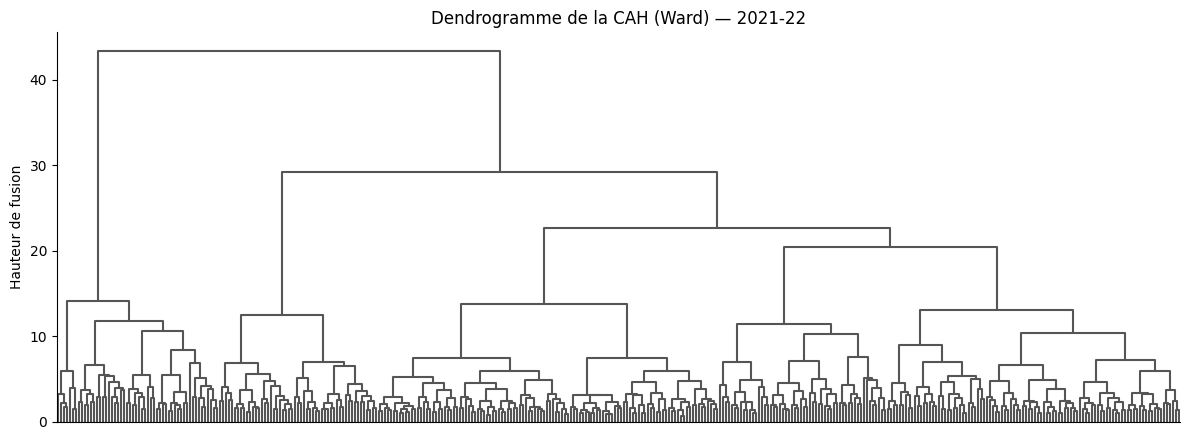

In [7]:
SAISON = 2021
K_MIN, K_MAX = 8, 20

saison = base[base["SEASON"] == SAISON].copy().reset_index(drop=True)
Z_saison = standardiser(saison)
X = Z_saison.to_numpy()
print(f"Saison {nom_saison(SAISON)} : {len(saison)} joueurs, {X.shape[1]} variables")

arbre = linkage(X, method="ward")

fig, ax = plt.subplots(figsize=(12, 4.5))
dendrogram(arbre, no_labels=True, color_threshold=0, above_threshold_color="#555555", ax=ax)
ax.set_title(f"Dendrogramme de la CAH (Ward) — {nom_saison(SAISON)}")
ax.set_ylabel("Hauteur de fusion")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Choisir le nombre de groupes : coude puis silhouette

Pour chaque k, on coupe l'arbre de la CAH en k groupes et on calcule :

- **l'inertie intra-groupe W(k)** : elle diminue toujours quand k augmente. On cherche un **coude**, c'est-à-dire le k à partir duquel ajouter un groupe fait beaucoup moins baisser W ;
- **l'indice de silhouette** : pour chaque joueur, s = (b − a) / max(a, b), où a est la distance moyenne aux joueurs de son groupe et b la distance moyenne aux joueurs du groupe voisin le plus proche. s est proche de 1 si le joueur est bien placé, proche de 0 s'il est à la frontière entre deux groupes. On prend la moyenne sur tous les joueurs.

On calcule aussi k = 2 à 7 pour voir la forme générale des courbes, mais le choix se fait entre 8 et 20.

In [8]:
def inertie_intra(X, labels):
    return sum(((X[labels == g] - X[labels == g].mean(axis=0)) ** 2).sum()
               for g in np.unique(labels))

lignes = []
for k in range(2, K_MAX + 1):
    lab = fcluster(arbre, k, criterion="maxclust")
    lignes.append({"k": k, "inertie_intra": inertie_intra(X, lab),
                   "silhouette": silhouette_score(X, lab)})
choix = pd.DataFrame(lignes).set_index("k")
choix["baisse_inertie"] = -choix["inertie_intra"].diff()
with pd.option_context("display.float_format", "{:.3f}".format):
    display(choix.loc[K_MIN:K_MAX])

K_OPT = int(choix.loc[K_MIN:K_MAX, "silhouette"].idxmax())
print(f"Nombre de groupes retenu (silhouette maximale entre {K_MIN} et {K_MAX}) : k = {K_OPT}")

,inertie_intra,silhouette,baisse_inertie
k,,,
8,2000.497,0.080,84.821
9,1922.407,0.083,78.091
10,1852.490,0.086,69.916
11,1787.757,0.092,64.733
12,1731.752,0.097,56.006
13,1678.649,0.095,53.102
14,1626.635,0.100,52.015
15,1586.436,0.100,40.198
16,1551.710,0.101,34.727


Nombre de groupes retenu (silhouette maximale entre 8 et 20) : k = 17


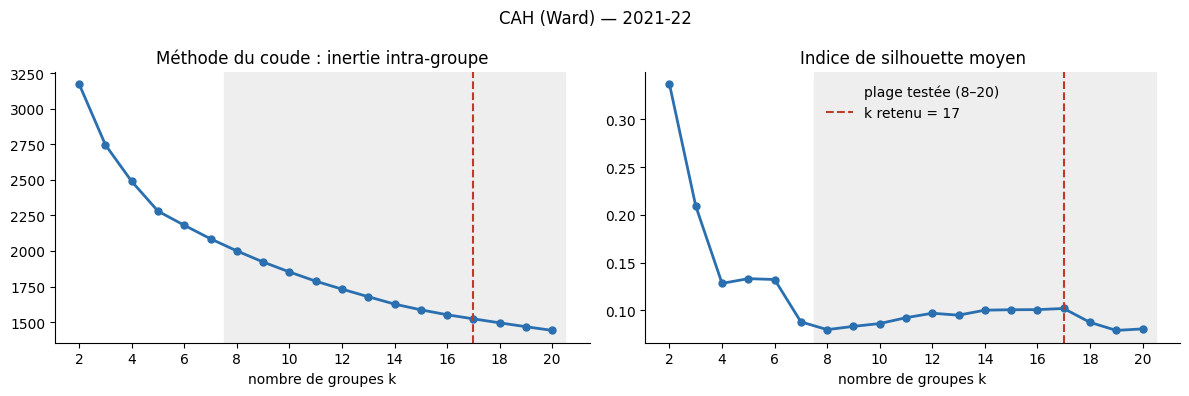

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titre in [(axes[0], "inertie_intra", "Méthode du coude : inertie intra-groupe"),
                       (axes[1], "silhouette", "Indice de silhouette moyen")]:
    ax.axvspan(K_MIN - 0.5, K_MAX + 0.5, color="#eeeeee", zorder=0, label=f"plage testée ({K_MIN}–{K_MAX})")
    ax.plot(choix.index, choix[col], color="#2a6fb0", lw=2, marker="o", ms=5)
    ax.axvline(K_OPT, color="#c0392b", lw=1.5, ls="--", label=f"k retenu = {K_OPT}")
    ax.set_title(titre); ax.set_xlabel("nombre de groupes k")
    ax.set_xticks(range(2, K_MAX + 1, 2))
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False)
fig.suptitle(f"CAH (Ward) — {nom_saison(SAISON)}")
plt.tight_layout()
plt.show()

**Lecture :**
- l'inertie diminue de façon régulière entre 8 et 20, **sans coude net** : la méthode du coude seule ne permet pas de trancher ;
- la silhouette est faible (autour de 0,1) et varie peu entre 8 et 20. Les joueurs ne forment pas des paquets bien séparés : les styles de jeu changent progressivement d'un joueur à l'autre. Les groupes obtenus restent utiles pour décrire des profils, mais il ne faut pas les présenter comme des « vraies » catégories naturelles ;
- la silhouette est nettement plus haute pour k = 2 : la séparation la plus forte dans les données est extérieurs / intérieurs ;
- entre 8 et 20, les silhouettes ne diffèrent souvent qu'à la 3e décimale. Le k retenu est donc fragile : un petit changement (seuil de minutes, choix des variables) peut le faire varier. La partie 9 le vérifie sur toutes les saisons.

## 7. Consolidation par k-means

La CAH ne revient jamais sur une fusion : un joueur mal placé au début le reste. On lance donc un **k-means initialisé avec les centres des groupes de la CAH**. Le k-means réaffecte chaque joueur au centre le plus proche puis recalcule les centres, jusqu'à stabilité. Cela diminue l'inertie intra-groupe et améliore en général la silhouette.

On vérifie que la consolidation ne change pas complètement les groupes avec l'**indice de Rand ajusté** (ARI) : 1 = partitions identiques, 0 = pas plus de ressemblance qu'au hasard.

In [10]:
lab_cah = fcluster(arbre, K_OPT, criterion="maxclust")
centres_cah = np.array([X[lab_cah == g].mean(axis=0) for g in np.unique(lab_cah)])

kmeans = KMeans(n_clusters=K_OPT, init=centres_cah, n_init=1, random_state=0).fit(X)
lab_km = kmeans.labels_

comparaison = pd.DataFrame({
    "inertie_intra": [inertie_intra(X, lab_cah), kmeans.inertia_],
    "silhouette": [silhouette_score(X, lab_cah), silhouette_score(X, lab_km)],
}, index=["CAH seule", "CAH + k-means"])
display(comparaison)
print("ARI entre les deux partitions :", round(adjusted_rand_score(lab_cah, lab_km), 2))

# Groupes finaux numérotés de 1 à k, du plus grand au plus petit
ordre = pd.Series(lab_km).value_counts().index
renum = {ancien: i + 1 for i, ancien in enumerate(ordre)}
saison["GROUPE"] = pd.Series(lab_km).map(renum).to_numpy()
centres = pd.DataFrame(kmeans.cluster_centers_, columns=VARIABLES)
centres.index = [renum[i] for i in range(K_OPT)]
centres = centres.sort_index()

,inertie_intra,silhouette
CAH seule,1523.01,0.10
CAH + k-means,1415.56,0.13


ARI entre les deux partitions : 0.57


## 8. Pourquoi ces joueurs sont-ils ensemble ?

Trois lectures complémentaires :

1. **Carte des centres** : pour chaque groupe, la valeur moyenne de chaque variable en écart-types par rapport à la moyenne de la saison. Rouge = au-dessus de la moyenne, bleu = en dessous.
2. **Traits dominants** : les 3 variables les plus éloignées de la moyenne pour chaque groupe.
3. **Joueurs représentatifs** : les joueurs les plus proches du centre du groupe, et les joueurs du groupe qui ont le plus joué.

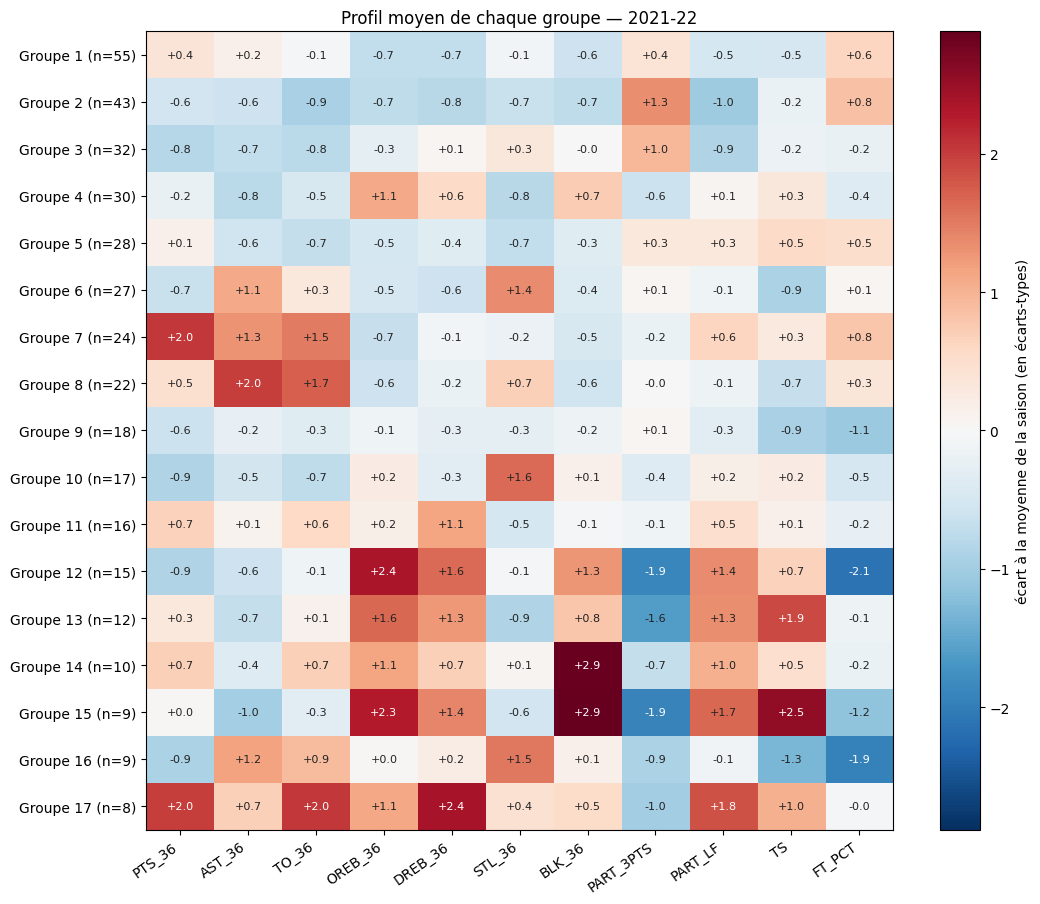

In [11]:
fig, ax = plt.subplots(figsize=(11, 0.45 * K_OPT + 1.5))
lim = np.nanmax(np.abs(centres.to_numpy()))
im = ax.imshow(centres.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=35, ha="right")
effectifs = saison["GROUPE"].value_counts().sort_index()
ax.set_yticks(range(K_OPT), [f"Groupe {g} (n={effectifs[g]})" for g in centres.index])
for i in range(K_OPT):
    for j in range(len(VARIABLES)):
        v = centres.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * lim else "#222222")
fig.colorbar(im, ax=ax, label="écart à la moyenne de la saison (en écarts-types)")
ax.set_title(f"Profil moyen de chaque groupe — {nom_saison(SAISON)}")
plt.tight_layout()
plt.show()

In [12]:
def traits(centre, n=3):
    top = centre.abs().sort_values(ascending=False).index[:n]
    return ", ".join(f"{'+' if centre[v] > 0 else '−'}{v}" for v in top)

# Distance de chaque joueur au centre de son groupe
dist = np.linalg.norm(X - centres.loc[saison["GROUPE"]].to_numpy(), axis=1)
saison["DIST_CENTRE"] = dist

resume = []
for g in centres.index:
    grp = saison[saison["GROUPE"] == g]
    resume.append({
        "groupe": g,
        "effectif": len(grp),
        "traits dominants": traits(centres.loc[g]),
        "joueurs les plus proches du centre": ", ".join(grp.nsmallest(4, "DIST_CENTRE")["PLAYER_NAME"]),
        "joueurs avec le plus de minutes": ", ".join(grp.nlargest(4, "MIN_TOTAL")["PLAYER_NAME"]),
    })
resume = pd.DataFrame(resume).set_index("groupe")
with pd.option_context("display.max_colwidth", None):
    display(resume)

,effectif,traits dominants,joueurs les plus proches du centre,joueurs avec le plus de minutes
groupe,,,,
1,55,"−DREB_36, −OREB_36, +FT_PCT","Kemba Walker, Lonnie Walker IV, Chris Duarte, Gordon Hayward","Saddiq Bey, Jalen Brunson, Buddy Hield, Anthony Edwards"
2,43,"+PART_3PTS, −PART_LF, −TO_36","Landry Shamet, Timothe Luwawu-Cabarrot, Justin Holiday, Corey Kispert","Patty Mills, Kevin Huerter, Justin Holiday, Duncan Robinson"
3,32,"+PART_3PTS, −PART_LF, −PTS_36","Torrey Craig, Taurean Prince, Maurice Harkless, Rodney McGruder","Dorian Finney-Smith, Royce O'Neale, Kelly Oubre Jr., Deni Avdija"
4,30,"+OREB_36, −STL_36, −AST_36","Daniel Theis, Keita Bates-Diop, Obi Toppin, Nassir Little","Scottie Barnes, Evan Mobley, Bobby Portis, Al Horford"
5,28,"−STL_36, −TO_36, −AST_36","Amir Coffey, Lauri Markkanen, Carmelo Anthony, Keldon Johnson","Mikal Bridges, Tyrese Maxey, Harrison Barnes, Tobias Harris"
6,27,"+STL_36, +AST_36, −TS","Marcus Smart, Eric Bledsoe, Raul Neto, Talen Horton-Tucker","Marcus Smart, Mike Conley, De'Anthony Melton, Killian Hayes"
7,24,"+PTS_36, +TO_36, +AST_36","Khris Middleton, Devin Booker, Shai Gilgeous-Alexander, Brandon Ingram","DeMar DeRozan, Jayson Tatum, Trae Young, James Harden"
8,22,"+AST_36, +TO_36, +STL_36","Lance Stephenson, Cameron Payne, Ricky Rubio, D'Angelo Russell","Tyrese Haliburton, Russell Westbrook, Fred VanVleet, Darius Garland"
9,18,"−FT_PCT, −TS, −PTS_36","CJ Elleby, Josh Jackson, Aaron Wiggins, Lamar Stevens","Andrew Wiggins, Ayo Dosunmu, Davion Mitchell, Darius Bazley"


**Statistiques réelles par groupe** (non standardisées, pour parler basket). Le pourcentage à 3 points du groupe est calculé sur les totaux du groupe (somme des 3 points réussis / somme des tentés) : les joueurs sans tentative ne comptent pas, ce qui respecte les NA. La colonne `part_sans_tir_3pts` donne la proportion de joueurs du groupe dont le `FG3_PCT` est NA.

In [13]:
reel = saison.groupby("GROUPE").agg(
    effectif=("PLAYER_ID", "size"),
    min_moy=("MIN_MOY", "mean"),
    titulaire_pct=("GS", lambda s: 100 * s.sum() / saison.loc[s.index, "GP"].sum()),
    pts_36=("PTS_36", "mean"), ast_36=("AST_36", "mean"),
    reb_36=("OREB_36", lambda s: (s + saison.loc[s.index, "DREB_36"]).mean()),
    blk_36=("BLK_36", "mean"), stl_36=("STL_36", "mean"),
    part_3pts_pct=("PART_3PTS", lambda s: 100 * s.mean()),
    fg3_pct_groupe=("FG3M", lambda s: 100 * s.sum() / saison.loc[s.index, "FG3A"].sum()),
    part_sans_tir_3pts=("FG3_PCT", lambda s: 100 * s.isna().mean()),
    ts_pct=("TS", lambda s: 100 * s.mean()),
    ft_pct=("FT_PCT", lambda s: 100 * s.mean()),
)
display(reel.round(1))

,effectif,min_moy,titulaire_pct,pts_36,ast_36,reb_36,blk_36,stl_36,part_3pts_pct,fg3_pct_groupe,part_sans_tir_3pts,ts_pct,ft_pct
GROUPE,,,,,,,,,,,,,
1,55,26.20,56.80,17.70,3.90,4.40,0.40,1.10,47.40,36.00,0.00,54.10,83.10
2,43,20.70,31.60,13.30,2.30,4.20,0.30,0.90,66.50,37.20,0.00,55.60,85.30
3,32,21.70,41.00,12.00,2.10,6.40,0.70,1.30,58.80,35.80,0.00,55.70,74.60
4,30,21.40,45.30,14.90,2.00,9.10,1.20,0.80,27.00,33.60,0.00,58.20,73.20
5,28,27.40,65.10,16.50,2.40,5.30,0.50,0.90,45.50,38.30,0.00,59.30,81.80
6,27,20.90,32.70,12.80,5.80,4.90,0.50,1.70,41.00,33.00,0.00,51.90,77.50
7,24,34.80,94.30,25.50,6.20,5.70,0.50,1.10,35.80,35.80,0.00,58.00,84.80
8,22,30.60,84.10,18.00,7.60,5.50,0.40,1.50,39.60,35.10,0.00,53.20,80.30
9,18,20.90,35.50,13.00,3.10,6.00,0.60,1.00,40.70,32.40,0.00,51.80,66.30


**Vue d'ensemble sur un plan.** Pour visualiser, on projette les joueurs sur les deux premiers axes d'une ACP (environ 57 % de la variance). Les points gris sont les joueurs, les numéros sont les centres des groupes. C'est seulement une aide visuelle : les groupes ont été formés avec les 11 variables, pas avec ces 2 axes.

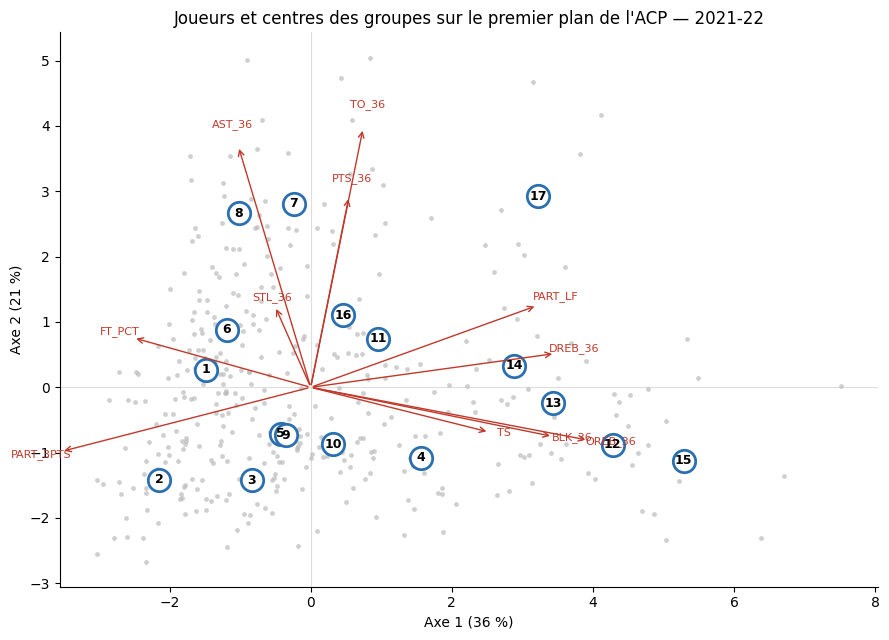

In [14]:
acp = PCA(n_components=2).fit(X)
P = acp.transform(X)
Pc = acp.transform(centres.to_numpy())

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(P[:, 0], P[:, 1], s=12, color="#bbbbbb", alpha=0.7, lw=0)
for g, (x, y) in zip(centres.index, Pc):
    ax.scatter(x, y, s=260, color="white", edgecolor="#2a6fb0", lw=2, zorder=3)
    ax.text(x, y, str(g), ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)

# Sens des axes : flèches des variables (corrélations avec les axes)
charges = acp.components_.T * np.sqrt(acp.explained_variance_)
# Même échelle sur les deux axes, choisie pour que toutes les flèches restent dans le graphique
echelle = 0.8 * np.abs(P).max(axis=0).min() / np.linalg.norm(charges, axis=1).max()
for v, (a, b) in zip(VARIABLES, charges):
    ax.annotate("", xy=(a * echelle, b * echelle), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1))
    ax.text(a * echelle * 1.08, b * echelle * 1.08, v, color="#c0392b", fontsize=8, ha="center")

r = acp.explained_variance_ratio_
ax.set_xlabel(f"Axe 1 ({100 * r[0]:.0f} %)"); ax.set_ylabel(f"Axe 2 ({100 * r[1]:.0f} %)")
ax.set_title(f"Joueurs et centres des groupes sur le premier plan de l'ACP — {nom_saison(SAISON)}")
ax.axhline(0, color="#dddddd", lw=0.8, zorder=0); ax.axvline(0, color="#dddddd", lw=0.8, zorder=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**À faire à partir de ces tableaux :** donner un nom à chaque groupe (par exemple « intérieur protecteur de cercle », « meneur créateur », « shooteur de banc ») en s'appuyant sur les traits dominants et les joueurs représentatifs, puis comparer avec les 12 archétypes de la partie 2.

## 9. Le choix de k est-il stable d'une saison à l'autre ?

On refait la même procédure (CAH, silhouette entre 8 et 20, consolidation k-means) pour chaque saison de 2003-04 à 2021-22. Si le k retenu change beaucoup d'une saison à l'autre alors que les silhouettes restent proches, cela confirme qu'il n'existe pas de nombre de groupes « naturel » et que le choix de k reste en partie une décision d'analyse.

In [15]:
def clustering_saison(s):
    sb = base[base["SEASON"] == s]
    Xs = standardiser(sb).to_numpy()
    arb = linkage(Xs, method="ward")
    sil = {k: silhouette_score(Xs, fcluster(arb, k, criterion="maxclust"))
           for k in range(K_MIN, K_MAX + 1)}
    k = max(sil, key=sil.get)
    lab = fcluster(arb, k, criterion="maxclust")
    cen = np.array([Xs[lab == g].mean(axis=0) for g in np.unique(lab)])
    km = KMeans(n_clusters=k, init=cen, n_init=1, random_state=0).fit(Xs)
    return {"saison": nom_saison(s), "joueurs": len(sb), "k_retenu": k,
            "silhouette_CAH": sil[k],
            "silhouette_CAH_kmeans": silhouette_score(Xs, km.labels_),
            "silhouette_min_8_20": min(sil.values()),
            "silhouette_max_8_20": max(sil.values())}

stabilite = pd.DataFrame([clustering_saison(s) for s in sorted(base["SEASON"].unique())]).set_index("saison")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(stabilite)
print("Fréquence des k retenus :")
print(stabilite["k_retenu"].value_counts().sort_index().to_string())

,joueurs,k_retenu,silhouette_CAH,silhouette_CAH_kmeans,silhouette_min_8_20,silhouette_max_8_20
saison,,,,,,
2003-04,325,11,0.110,0.138,0.096,0.110
2004-05,335,10,0.114,0.138,0.083,0.114
2005-06,323,10,0.115,0.138,0.086,0.115
2006-07,328,10,0.126,0.136,0.091,0.126
2007-08,324,11,0.108,0.124,0.096,0.108
2008-09,329,8,0.122,0.137,0.099,0.122
2009-10,331,11,0.104,0.131,0.092,0.104
2010-11,338,9,0.118,0.132,0.089,0.118
2011-12,331,11,0.108,0.125,0.083,0.108


Fréquence des k retenus :
k_retenu
8     3
9     1
10    4
11    4
12    1
14    1
15    1
17    1
20    3


## 10. Export

Le fichier contient, pour la saison analysée, chaque joueur avec son groupe et ses variables. Il pourra servir plus tard pour décrire la composition des équipes dans le modèle de prédiction des matchs.

In [16]:
colonnes_export = ["PLAYER_ID", "PLAYER_NAME", "SEASON", "EQUIPES", "GP", "GS", "MIN_TOTAL",
                   "GROUPE", "DIST_CENTRE", "FG_PCT", "FG3_PCT", "FT_PCT"] + \
                  [v for v in VARIABLES if v not in ("FT_PCT",)]
fichier = f"groupes_joueurs_{SAISON}.csv"
saison[colonnes_export].sort_values(["GROUPE", "DIST_CENTRE"]).to_csv(fichier, index=False)
print("Export :", fichier)

Export : groupes_joueurs_2021.csv
